# Visualizations

This notebook is for charts, plots, and dashboard-ready visuals based on the analysis.

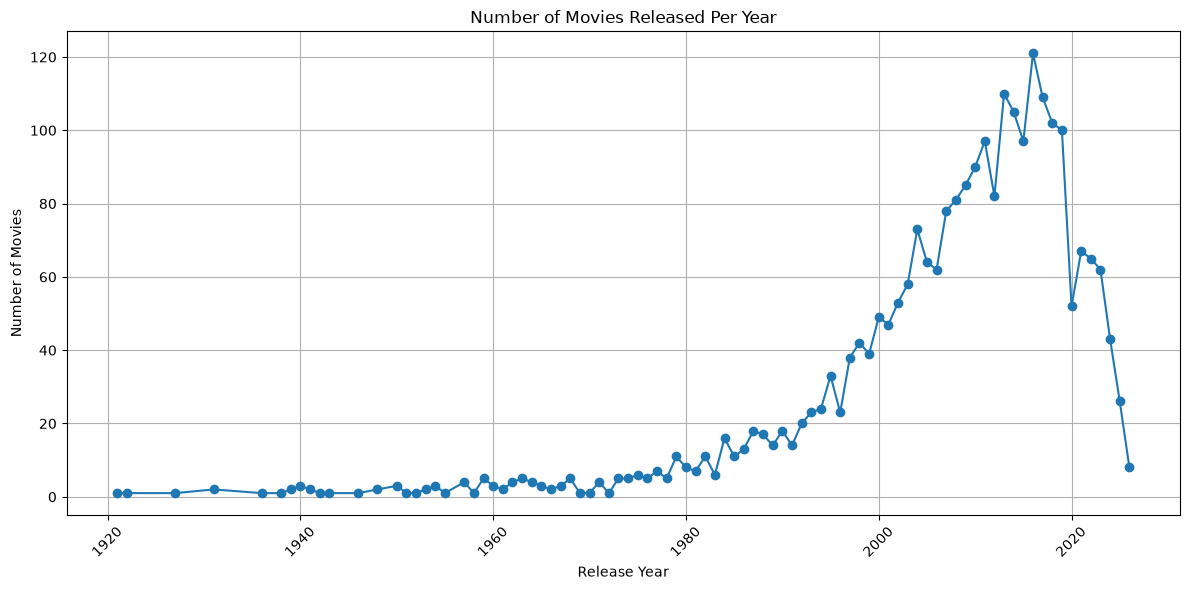

In [ ]:
# 1. Movies released per year – Line chart

import pandas as pd
import matplotlib.pyplot as plt

# Load movie dataset
movies_df = pd.read_csv("C:\\Users\\acer\\Documents\\TMDB Project\\ReelInsights\\outputs\\cleaned_movies_data.csv")

# Convert the object date value into pandas readable datetime
movies_df["release_date"] = pd.to_datetime(
    movies_df["release_date"]
)

# Extract release year
movies_df["release_year"] = movies_df["release_date"].dt.year

# Count movies released per year
movies_per_year = (
    movies_df.dropna(subset=["release_year"])
    .groupby("release_year")["movie_id"]
    .nunique()
)

# Create line chart (12 is width and 6 is height)
plt.figure(figsize=(12,6))

plt.plot(
    movies_per_year.index,
    movies_per_year.values,
    marker = 'o'
)

plt.title("Number of Movies Released Per Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Movies")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

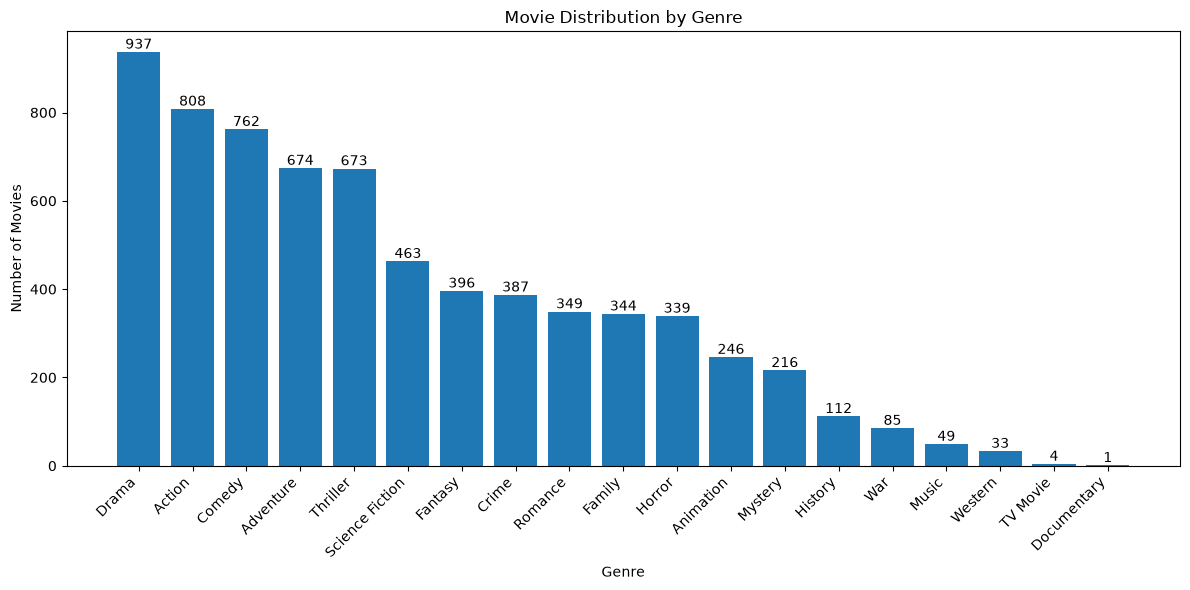

In [ ]:
# 2. Genre distribution – Bar chart

import pandas as pd
import matplotlib.pyplot as plt

# Step 1: Load datasets
movies_df = pd.read_csv("C:\\Users\\acer\\Documents\\TMDB Project\\ReelInsights\\outputs\\cleaned_movies_data.csv")
movie_genres_df = pd.read_csv("C:\\Users\\acer\\Documents\\TMDB Project\\ReelInsights\\outputs\\cleaned_movie_genres.csv")
genres_df = pd.read_csv("C:\\Users\\acer\\Documents\\TMDB Project\\ReelInsights\\data\\genres.csv")

# Step 2: Merge genre data
genre_data = movie_genres_df.merge(
    genres_df,
    on="genre_id",
    how="inner"
)

# Step 3: Count movies per genre
genre_counts = (
    genre_data.groupby("genre_name")["movie_id"]
    .nunique()
    .sort_values(ascending=False)
)

# Step 4: Create bar chart

plt.figure(figsize=(12,6))

plt.bar(
    genre_counts.index,
    genre_counts.values
)

plt.title("Movie Distribution by Genre")
plt.xlabel("Genre")
plt.ylabel("Number of Movies")
plt.xticks(rotation=45, ha="right")

for i, value in enumerate(genre_counts.values):
    plt.text(i, value, str(value), ha="center", va="bottom")

plt.tight_layout()
plt.show()

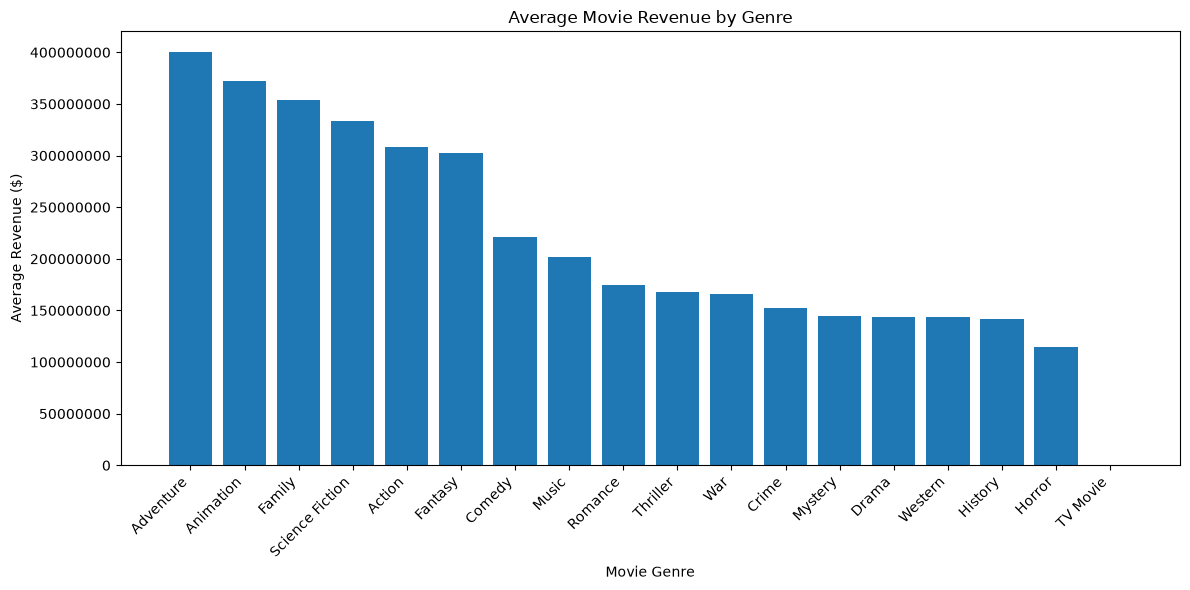

In [ ]:
# 3. Revenue by genre – Bar chart

import pandas as pd
import matplotlib.pyplot as plt

# Step 1: Load datasets
movies_df = pd.read_csv("C:\\Users\\acer\\Documents\\TMDB Project\\ReelInsights\\outputs\\cleaned_movies_data.csv")
movie_genres_df = pd.read_csv("C:\\Users\\acer\\Documents\\TMDB Project\\ReelInsights\\outputs\\cleaned_movie_genres.csv")
genres_df = pd.read_csv("C:\\Users\\acer\\Documents\\TMDB Project\\ReelInsights\\data\\genres.csv")

# Step 2: Convert budget and revenue to numeric
movies_df["revenue"] = pd.to_numeric(movies_df["revenue"])

# Step 3: Exclude unknown revenue values
valid_data = movies_df[
    movies_df["revenue"].notna() &
    (movies_df["revenue"] > 0)
].copy()

# Step 4: Merge movie and genre data
genre_data = movie_genres_df.merge(
    genres_df,
    on="genre_id",
    how="inner"
)

genre_data = genre_data.merge(
    valid_data[["movie_id","revenue"]],
    on="movie_id",
    how="inner"
)

# Step 5: Calculate average revenue per genre
avg_revenue_per_genre = (
    genre_data.groupby("genre_name")["revenue"]
    .mean()
    .sort_values(ascending=False)
)

# Step 6: Create bar chart
plt.figure(figsize=(12,6))

plt.bar(
    avg_revenue_per_genre.index,
    avg_revenue_per_genre.values
)

plt.title("Average Movie Revenue by Genre")
plt.xlabel("Movie Genre")
plt.ylabel("Average Revenue ($)")
plt.xticks(rotation=45, ha="right")

# Step 7: Format Y-axis with revenue values
plt.ticklabel_format(
    style="plain",
    axis="y"
)

plt.tight_layout()
plt.show()

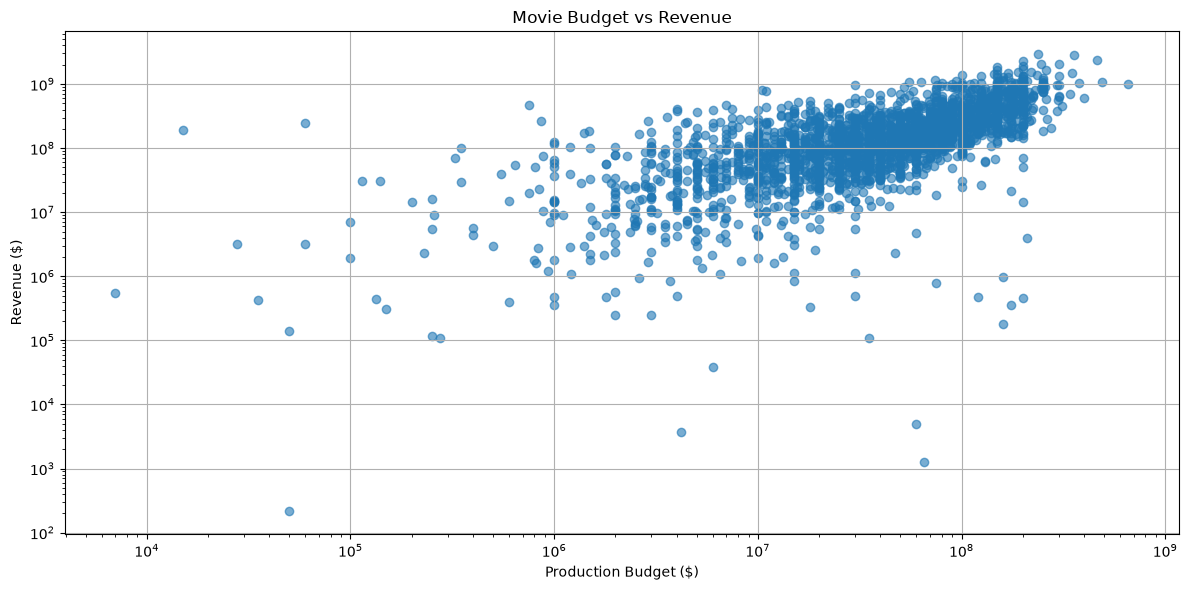

In [ ]:
# 4. Budget vs revenue – Scatter plot

import pandas as pd
import matplotlib.pyplot as plt

# Step 1: Load movie dataset
movies_df = pd.read_csv("C:\\Users\\acer\\Documents\\TMDB Project\\ReelInsights\\outputs\\cleaned_movies_data.csv")

movies_df["budget"] = pd.to_numeric(
    movies_df["budget"]
)

movies_df["revenue"] = pd.to_numeric(
    movies_df["revenue"]
)

# Step 3: Select movies with valid financial data
financial_df = movies_df[
    (movies_df["budget"] > 0) &
    (movies_df["revenue"] > 0)
].copy()

# Step 4: Create scatter plot
plt.figure(figsize=(12, 6))

plt.scatter(
    financial_df["budget"],
    financial_df["revenue"],
    alpha=0.6
)

plt.title("Movie Budget vs Revenue")
plt.xlabel("Production Budget ($)")
plt.ylabel("Revenue ($)")

plt.ticklabel_format(style="plain", axis="both")

plt.grid(True)
plt.tight_layout()
plt.show()

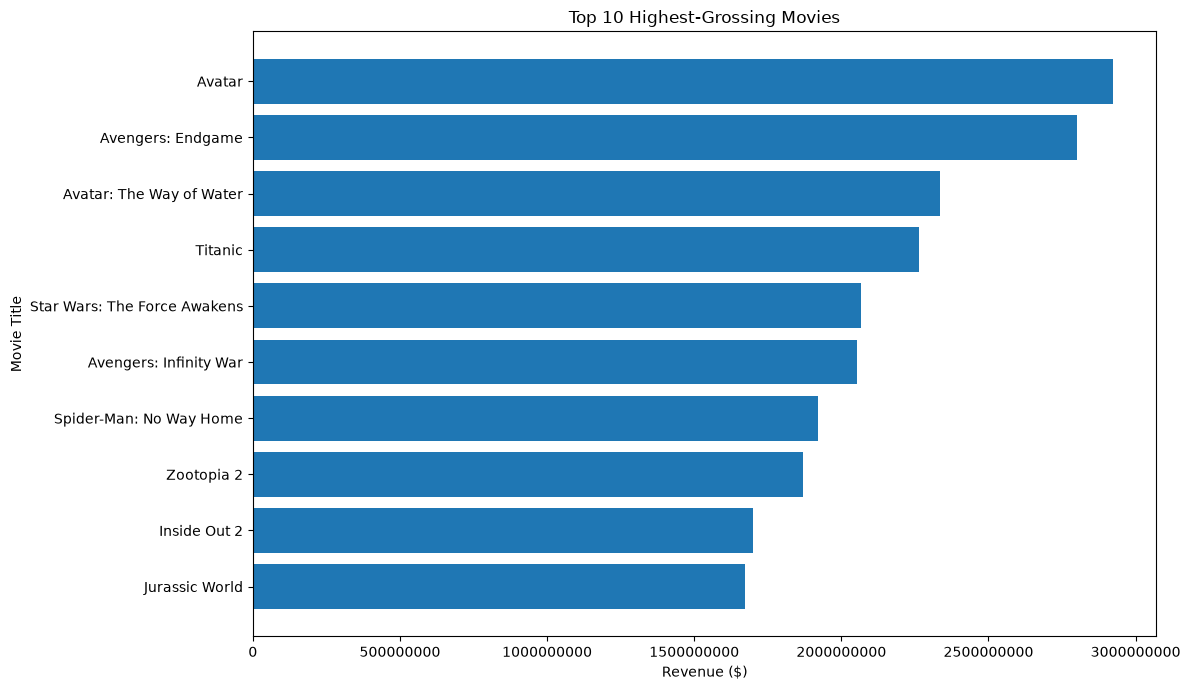

In [ ]:
# 5. Top 10 movies by revenue – Bar chart

import pandas as pd
import matplotlib.pyplot as plt

# Step 1: Load movie dataset
movies_df = pd.read_csv("C:\\Users\\acer\\Documents\\TMDB Project\\ReelInsights\\outputs\\cleaned_movies_data.csv")

movies_df["revenue"] = pd.to_numeric(
    movies_df["revenue"]
)

valid_movies = movies_df[
    movies_df["revenue"].notna() &
    (movies_df["revenue"] > 0)
].copy()

top_10_movies = valid_movies.nlargest(
    10, "revenue"
).sort_values("revenue", ascending=True)

plt.figure(figsize=(12,7))

plt.barh(
    top_10_movies["title"],
    top_10_movies["revenue"]
)

plt.title("Top 10 Highest-Grossing Movies")
plt.xlabel("Revenue ($)")
plt.ylabel("Movie Title")

plt.ticklabel_format(style="plain", axis="x")

plt.tight_layout()
plt.show()

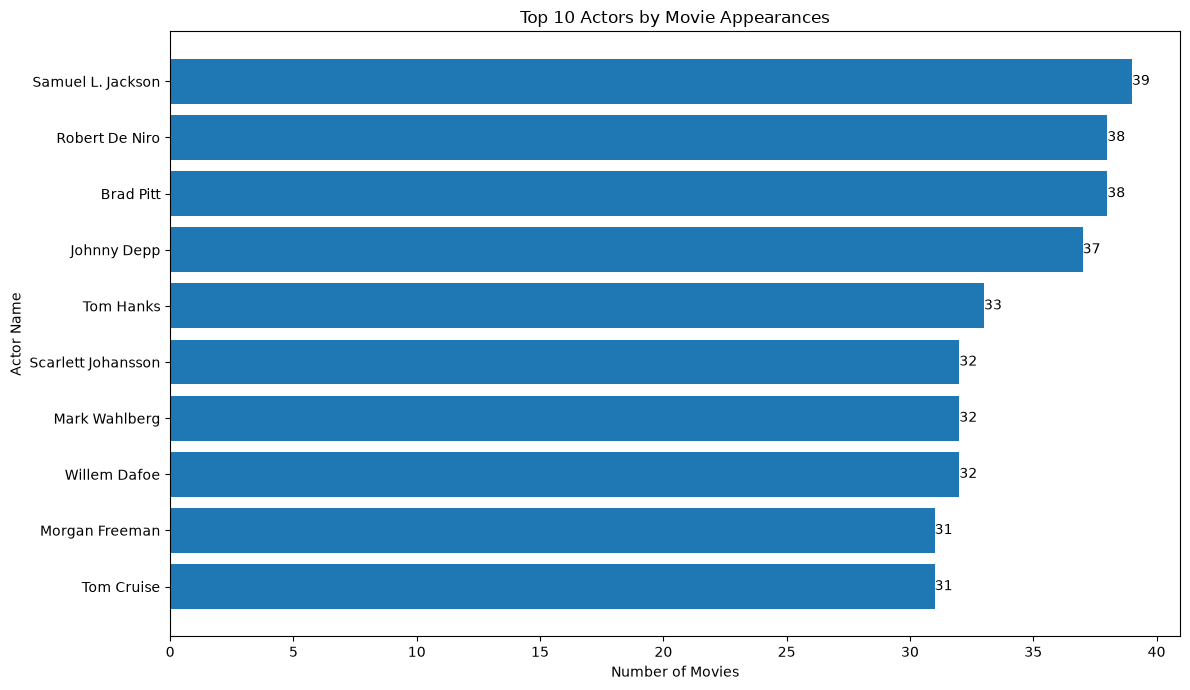

In [ ]:
# 6. Top 10 actors by appearances – Bar chart

import pandas as pd
import matplotlib.pyplot as plt

cast_df = pd.read_csv("C:\\Users\\acer\\Documents\\TMDB Project\\ReelInsights\\outputs\\cleaned_cast.csv")

#Count unique movies per actor
actor_counts = (
    cast_df.groupby(["person_id","actor_name"])["movie_id"]
    .nunique()
    .reset_index(name="total_movies")
)

#Select top 10 actors
top_10_actors = actor_counts.nlargest(
    10, "total_movies"
).sort_values(by=("total_movies"),ascending=True)

plt.figure(figsize=(12,7))

plt.barh(
    top_10_actors["actor_name"],
    top_10_actors["total_movies"]
)

plt.title("Top 10 Actors by Movie Appearances")
plt.xlabel("Number of Movies")
plt.ylabel("Actor Name")

# Display values
for i, value in enumerate(top_10_actors["total_movies"]):
    plt.text(value, i, str(value), va="center")

plt.tight_layout()
plt.show()

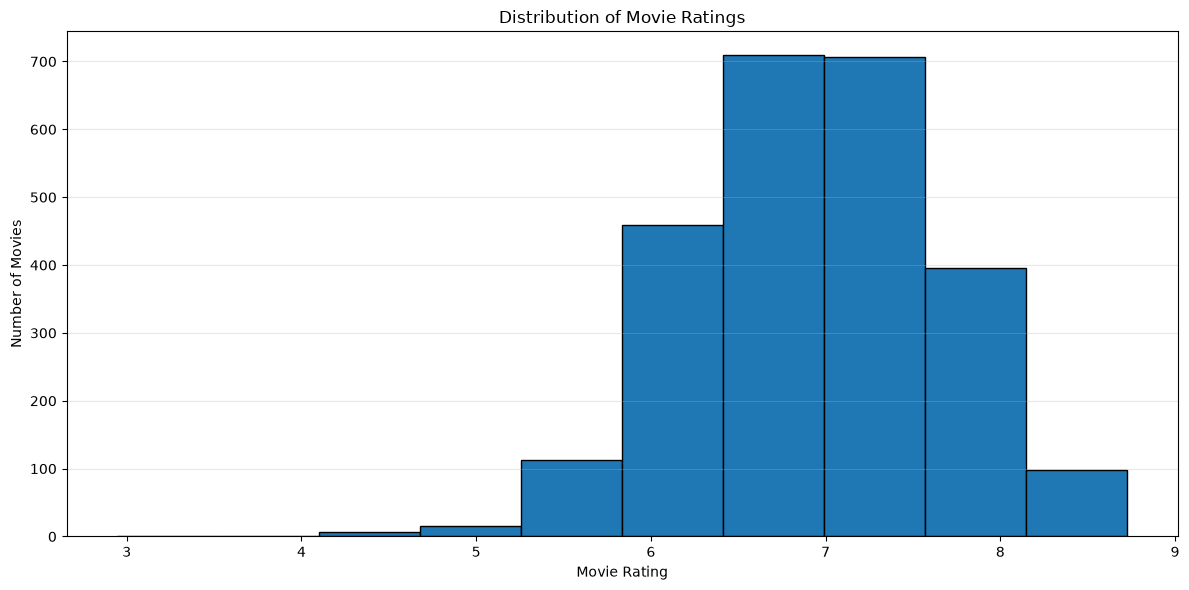

In [ ]:
# 7. Movie ratings distribution – Histogram

import pandas as pd
import matplotlib.pyplot as plt

movies_df = pd.read_csv("C:\\Users\\acer\\Documents\\TMDB Project\\ReelInsights\\outputs\\cleaned_movies_data.csv")

movies_df["vote_average"] = pd.to_numeric(
    movies_df["vote_average"]
)

#Select valid ratings
ratings_df = movies_df[
    movies_df["vote_average"].notna() &
    (movies_df["vote_average"] >= 0) &
    (movies_df["vote_average"] <= 10)
].copy()

#Create histogram
plt.figure(figsize=(12, 6))

plt.hist(
    ratings_df["vote_average"],
    bins=10,
    edgecolor="black"
)

plt.title("Distribution of Movie Ratings")
plt.xlabel("Movie Rating")
plt.ylabel("Number of Movies")

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

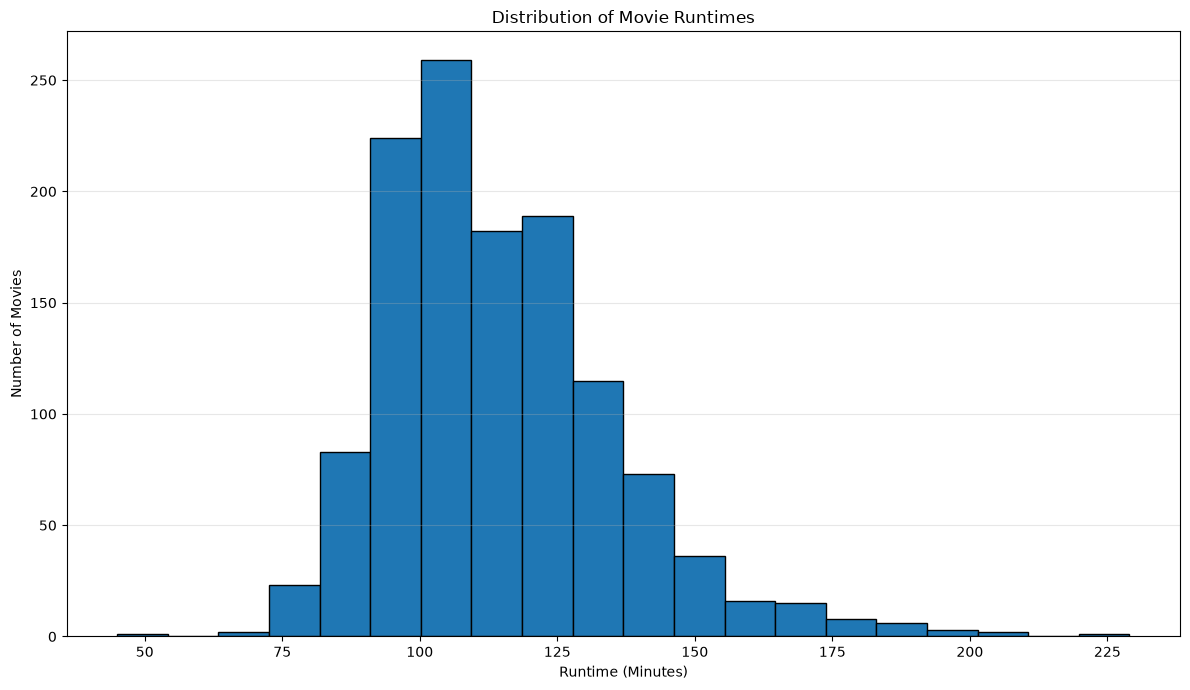

In [ ]:
# 8. Runtime distribution – Histogram

import pandas as pd
import matplotlib.pyplot as plt

movies_df =  pd.read_csv("C:\\Users\\acer\\Documents\\TMDB Project\\ReelInsights\\outputs\\cleaned_movies_data.csv")

movies_df["runtime"] = pd.to_numeric(
    movies_df["runtime"]
)

corrected_runtime = movies_df[
    movies_df["runtime"].notna() &
    movies_df["runtime"] > 0
].copy()

plt.figure(figsize=(12,7))
plt.hist(
    corrected_runtime["runtime"],
    bins=20,
    edgecolor="black"
)
plt.title("Distribution of Movie Runtimes")
plt.xlabel("Runtime (Minutes)")
plt.ylabel("Number of Movies")

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

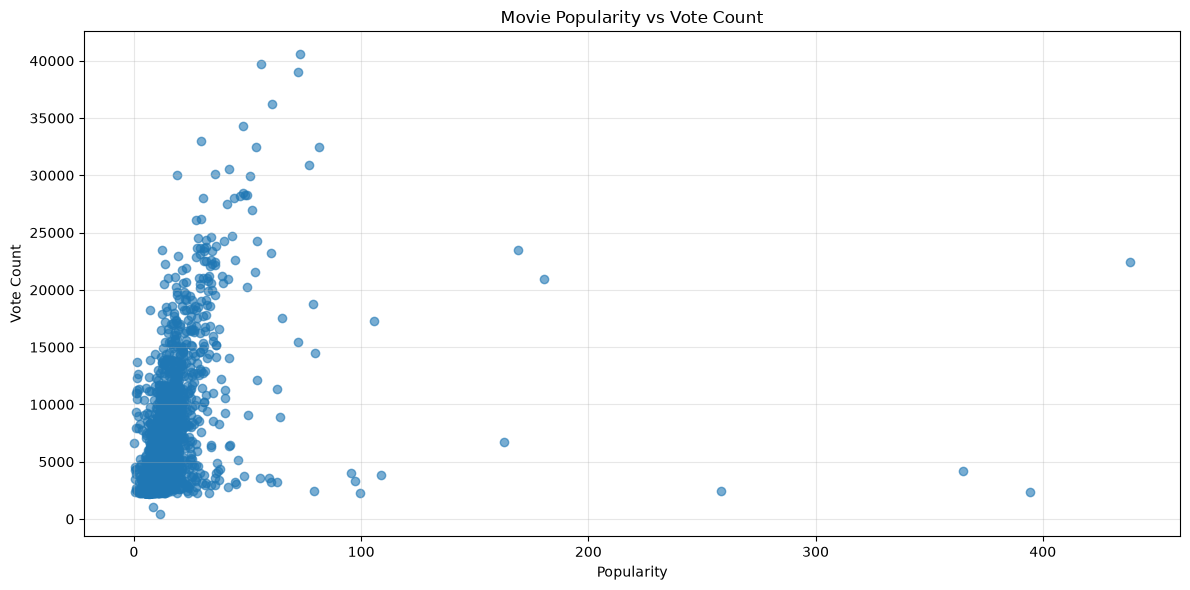

In [ ]:
# 9. Popularity vs vote count – Scatter plot

import pandas as pd
import matplotlib.pyplot as plt


movies_df = pd.read_csv("C:\\Users\\acer\\Documents\\TMDB Project\\ReelInsights\\outputs\\cleaned_movies_data.csv")


movies_df["popularity"] = pd.to_numeric(
    movies_df["popularity"], errors="coerce"
)

movies_df["vote_count"] = pd.to_numeric(
    movies_df["vote_count"]
)

analysis_df = movies_df[
    movies_df["popularity"].notna() &
    movies_df["vote_count"].notna() &
    (movies_df["popularity"] >= 0) &
    (movies_df["vote_count"] >= 0)
].copy()


plt.figure(figsize=(12, 6))

plt.scatter(
    analysis_df["popularity"],
    analysis_df["vote_count"],
    alpha=0.6
)

plt.title("Movie Popularity vs Vote Count")
plt.xlabel("Popularity")
plt.ylabel("Vote Count")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

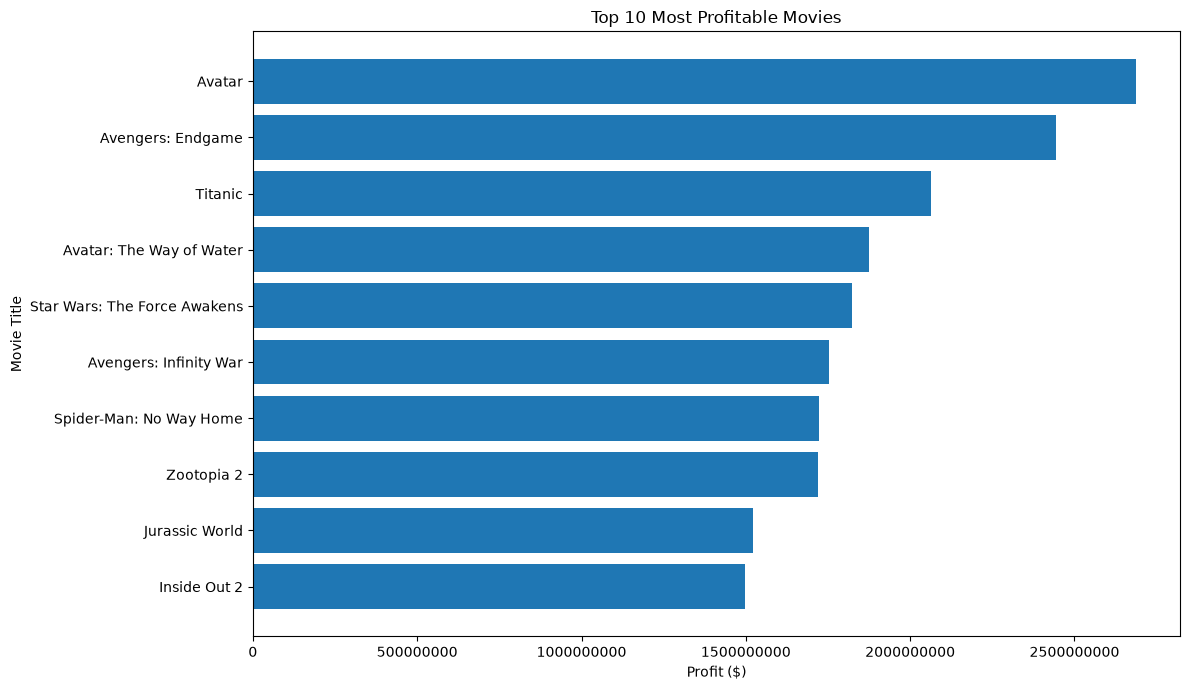

In [ ]:
# 10. Profit and ROI analysis – Bar chart

import pandas as pd
import matplotlib.pyplot as plt

movies_df = pd.read_csv("C:\\Users\\acer\\Documents\\TMDB Project\\ReelInsights\\outputs\\cleaned_movies_data.csv")

movies_df["budget"] = pd.to_numeric(
    movies_df["budget"], errors="coerce"
)

movies_df["revenue"] = pd.to_numeric(
    movies_df["revenue"], errors="coerce"
)

financial_df = movies_df[
    (movies_df["budget"] > 0) &
    (movies_df["revenue"] > 0)
].copy()

financial_df["profit"] = (
    financial_df["revenue"] - financial_df["budget"]
)

top_10_profit = financial_df.nlargest(
    10, "profit"
).sort_values(
    by="profit",
    ascending=True
)

plt.figure(figsize=(12, 7))

plt.barh(
    top_10_profit["title"],
    top_10_profit["profit"]
)

plt.title("Top 10 Most Profitable Movies")
plt.xlabel("Profit ($)")
plt.ylabel("Movie Title")
plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.show()